In [ ]:
# ==============================================================================
# Step 0: Initial Setup and Library Installation
# This script ensures all necessary Python libraries are installed and checks
# their versions for consistency and reproducibility in a Colab environment.
# ==============================================================================

# Install required libraries silently
!pip install -q morfessor nltk pandas scikit-learn matplotlib seaborn

# Optional: Install kivy for GUI on a local machine only
# !pip install kivy

# ==============================================================================
# Step 1: Import all required libraries
# ==============================================================================
import nltk
import pandas as pd
import re
import morfessor
import sklearn
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# Step 2: Check library versions for reproducibility
# This helps ensure the environment is consistent across different runs.
# ==============================================================================
libraries = {
    "nltk": nltk,
    "morfessor": morfessor,
    "numpy": np,
    "pandas": pd,
    "sklearn": sklearn,
    "matplotlib": matplotlib,
    "seaborn": sns
}

print("Library versions:")
print("-" * 25)
for name, lib in libraries.items():
    try:
        print(f"{name:<12}: {lib.__version__}")
    except AttributeError:
        print(f"{name:<12}: version not found")
    except Exception as e:
        print(f"{name:<12}: Error checking version - {e}")

# ==============================================================================
# Step 3: Optional check for Kivy (for local GUI development)
# This is not supported in a typical Colab notebook.
# ==============================================================================
try:
    import kivy
    print(f"\nkivy      : {kivy.__version__}")
except ModuleNotFoundError:
    print("\nkivy is not installed or not supported in this environment.")
except Exception as e:
    print(f"\nkivy      : Error importing - {e}")


Library versions:
-------------------------
nltk        : 3.9.1
morfessor   : 2.0.6
numpy       : 2.0.2
pandas      : 2.2.2
sklearn     : 1.6.1
matplotlib  : 3.10.0
seaborn     : 0.13.2

kivy is not installed or not supported in this environment.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==============================================================================
# Step 0: Initial Setup and Library Installation
# This script ensures all necessary Python libraries are installed before
# proceeding with data cleaning and processing.
# ==============================================================================
!pip install -q tqdm joblib pandas

# ==============================================================================
# Step 1: Import all required libraries
# ==============================================================================
import os
import zipfile
import glob
import re
from collections import Counter
import pandas as pd
from tqdm import tqdm
from joblib import Parallel, delayed
from pathlib import Path

# ==============================================================================
# Step 2: Define and manage file paths
# Using pathlib.Path ensures a consistent and cross-platform way to handle paths.
# ==============================================================================
# --- Input Paths ---
zip_path = Path("/content/Corpora (3).zip")
extract_folder = Path("/content/uploaded_files/Corpora_extracted")

# --- Output Paths ---
cleaned_file_path = Path("/content/cleaned_isizulu_sentences.txt")
word_freq_path = Path("/content/word_frequencies.csv")

# ==============================================================================
# Step 3: Extract ZIP archive if it doesn't already exist
# This prevents re-extraction on subsequent runs, saving time.
# ==============================================================================
if not extract_folder.exists():
    extract_folder.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        print(f" Extracting ZIP archive to: {extract_folder}")
        zip_ref.extractall(extract_folder)
    print(f" ZIP extraction complete.")
else:
    print(f" ZIP already extracted at: {extract_folder}")

# Find all .txt files recursively within the extracted folder
file_list = glob.glob(str(extract_folder / '**/*.txt'), recursive=True)
print(f" Found {len(file_list)} .txt files to process.")

# ==============================================================================
# Step 4: Enhanced function to clean isiZulu sentences
# This function standardizes text by lowercasing and removing irrelevant
# characters, while preserving important isiZulu-specific elements.
# ==============================================================================
def clean_sentence(sentence):
    """
    Cleans a single sentence by:
    1. Trimming leading/trailing whitespace and converting to lowercase.
    2. Replacing hyphens with spaces to split compound words.
    3. Removing numbers, symbols, and most punctuation.
    4. Preserving isiZulu-specific characters and orthography, including
       vowels (a, e, i, o, u), consonants, and click sounds (c, q, x).
    5. Normalizing multiple spaces to a single space.

    Args:
        sentence (str): The raw input sentence.

    Returns:
        str or None: The cleaned sentence, or None if the sentence is empty
                     after cleaning.
    """
    sentence = sentence.strip().lower()

    # IMPROVEMENT: Replace hyphens with spaces to correctly tokenize
    # compound words like "abantwana-bakhe".
    sentence = sentence.replace('-', ' ')

    # Define a set of allowed characters and patterns. This is more explicit
    # and readable than a negative regex. Note that '`' and `’` are kept
    # for apostrophes. Underscores are also allowed.
    allowed_chars_regex = r"[^a-zcqxys’'\- _]"

    sentence = re.sub(allowed_chars_regex, "", sentence)
    sentence = re.sub(r"\s+", " ", sentence)

    return sentence if len(sentence) > 0 else None

# ==============================================================================
# Step 5: Process files in parallel to speed up the operation
# This function is designed to be executed by joblib for parallel processing.
# ==============================================================================
def process_file(file_path):
    """
    Reads a single text file, cleans each sentence, and counts word frequencies.

    Args:
        file_path (str): The path to the file to process.

    Returns:
        tuple: A tuple containing a list of cleaned sentences and a word Counter.
    """
    local_cleaned = []
    local_counter = Counter()
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                cleaned = clean_sentence(line)
                if cleaned:
                    local_cleaned.append(cleaned)
                    local_counter.update(cleaned.split())
    except Exception as e:
        print(f"Warning: Could not process {file_path}. Error: {str(e)}", flush=True)
    return local_cleaned, local_counter

# Execute the file processing in parallel using all available CPU cores
print("🚀 Starting parallel file processing...")
results = Parallel(n_jobs=-1, backend='loky')(
    delayed(process_file)(fp) for fp in tqdm(file_list, desc="Processing files")
)
print("✅ Parallel processing complete.")

# ==============================================================================
# Step 6: Combine the results from all parallel processes
# ==============================================================================
cleaned_sentences = []
word_counter = Counter()
for sentences, counter in results:
    cleaned_sentences.extend(sentences)
    word_counter.update(counter)

print("\n Data processing summary:")
print(f" - Total sentences cleaned: {len(cleaned_sentences):,}")
print(f" - Total unique words: {len(word_counter):,}")
print(f" - Total words extracted: {sum(word_counter.values()):,}")

# ==============================================================================
# Step 7: Save the cleaned data to output files
# This makes the processed data available for subsequent scripts.
# ==============================================================================
# Save cleaned sentences to a text file
with open(cleaned_file_path, 'w', encoding='utf-8') as out_file:
    for sentence in cleaned_sentences:
        out_file.write(sentence + "\n")
print(f" Cleaned sentences saved to: {cleaned_file_path}")

# Save word frequencies to a CSV file, sorted by frequency
word_freq_df = pd.DataFrame(word_counter.items(), columns=['word', 'frequency'])
word_freq_df = word_freq_df.sort_values(by='frequency', ascending=False)
word_freq_df.to_csv(word_freq_path, index=False, encoding='utf-8')
print(f" Word frequencies saved to: {word_freq_path}")

print("\n All data processing and saving tasks completed successfully!")

🔄 Extracting ZIP archive to: /content/uploaded_files/Corpora_extracted
✅ ZIP extraction complete.
✅ Found 412 .txt files to process.
🚀 Starting parallel file processing...


Processing files: 100%|██████████| 412/412 [00:25<00:00, 16.18it/s]


✅ Parallel processing complete.

📊 Data processing summary:
 - Total sentences cleaned: 1,391,422
 - Total unique words: 1,284,977
 - Total words extracted: 17,529,395
✅ Cleaned sentences saved to: /content/cleaned_isizulu_sentences.txt
✅ Word frequencies saved to: /content/word_frequencies.csv

🎉 All data processing and saving tasks completed successfully!


[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Package brown is already up-to-date!


📖 Loading pre-cleaned sentences...
✅ Loaded 1385582 cleaned sentences
📝 Building isiZulu vocabulary...
✅ Vocabulary saved. Total isiZulu words: 1263172
✅ Tokenizer saved. Vocab size: 31
🔄 Generating training data...
✅ Dataset saved: /content/isizulu_spellchecker_dataset.csv, total entries: 296407

🚀 Starting training run 1/2 at 15:23:30...
Epoch 1/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 725s 5s/step - accuracy: 0.6551 - auc_3: 0.5470 - loss: 0.6408 - precision: 0.3591 - recall: 0.0258 - val_accuracy: 0.7181 - val_auc_3: 0.7337 - val_loss: 0.5612 - val_precision: 0.5965 - val_recall: 0.4737 - learning_rate: 0.0010
Epoch 2/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 702s 5s/step - accuracy: 0.7548 - auc_3: 0.7859 - loss: 0.5166 - precision: 0.6706 - recall: 0.5289 - val_accuracy: 0.8192 - val_auc_3: 0.8774 - val_loss: 0.4090 - val_precision: 0.7343 - val_recall: 0.7116 - learning_rate: 0.0010
Epoch 3/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 706s 5s/step - accuracy: 0.8197 - auc_3: 0.8765 - loss: 0.4123 - precision: 

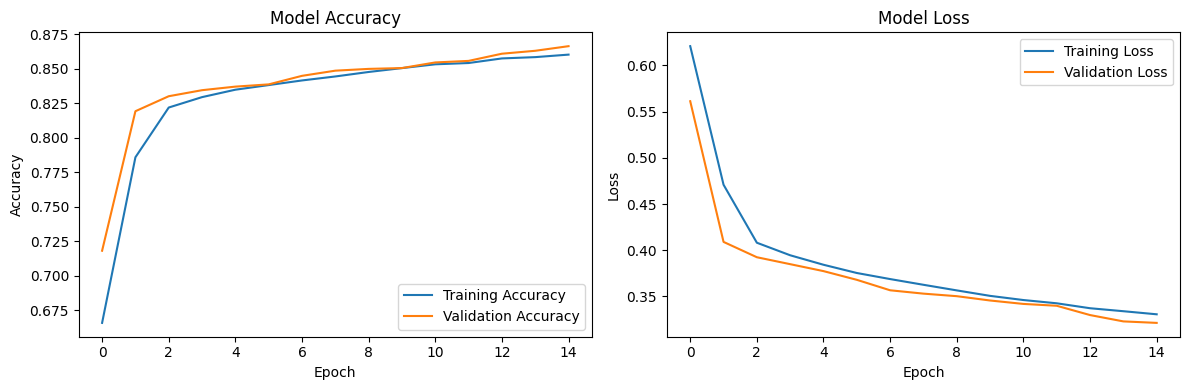


🔍 Detailed evaluation for best model:


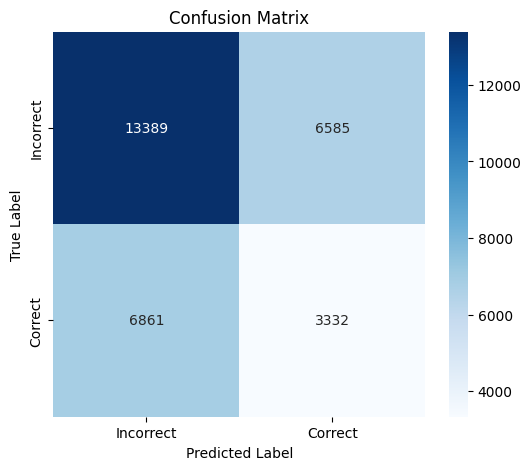


📋 Classification Report:
              precision    recall  f1-score   support

   Incorrect       0.66      0.67      0.67     19974
     Correct       0.34      0.33      0.33     10193

    accuracy                           0.55     30167
   macro avg       0.50      0.50      0.50     30167
weighted avg       0.55      0.55      0.55     30167


📊 FINAL RESULTS ACROSS 5 RUNS
Accuracy:  0.8653 ± 0.0012
Precision: 0.8095 ± 0.0020
Recall:    0.7846 ± 0.0012
AUC:       0.9306 ± 0.0004

📈 Individual run results:
Run 1: Acc=0.8665, Prec=0.8115, Rec=0.7858, AUC=0.9311
Run 2: Acc=0.8641, Prec=0.8074, Rec=0.7834, AUC=0.9302

✅ Best model saved at: /content/isizulu_spellchecker_model/spellchecker_full.keras


In [ ]:
# ==============================================================================
# Enhanced isiZulu Spell Checker with Deep Learning and Word Suggestions
# ==============================================================================
# Fix: Added python-Levenshtein to the installation list
!pip install -q tensorflow nltk pandas python-Levenshtein

# ==============================================================================
# Import all required libraries
# ==============================================================================
from pathlib import Path
import re
import json
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import nltk
import pandas as pd
import random
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import Levenshtein
import time

# Download Brown corpus for filtering English words
nltk.download('brown')

# ==============================================================================
# Define paths and hyperparameters
# ==============================================================================
CLEANED_SENTENCES_PATH = Path("/content/cleaned_isizulu_sentences.txt")
DATASET_PATH = Path("/content/isizulu_spellchecker_dataset.csv")
MODEL_DIR = Path("/content/isizulu_spellchecker_model")
TOKENIZER_PATH = MODEL_DIR / "tokenizer.json"
MODEL_PATH = MODEL_DIR / "spellchecker_full.keras"

MAX_SEQ_LEN = 32
EMBEDDING_DIM = 150
LSTM_UNITS = 128
BATCH_SIZE = 2048
EPOCHS = 15
NUM_RUNS = 2

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# ==============================================================================
# Load pre-cleaned data
# ==============================================================================
print("📖 Loading pre-cleaned sentences...")
cleaned_sentences = CLEANED_SENTENCES_PATH.read_text(encoding='utf-8').splitlines()
cleaned_sentences = [line.strip() for line in cleaned_sentences if line.strip()]
print(f"✅ Loaded {len(cleaned_sentences)} cleaned sentences")

# ==============================================================================
# Build vocabulary from cleaned sentences
# ==============================================================================
print(" Building isiZulu vocabulary...")
isizulu_vocabulary = set()
for sentence in cleaned_sentences:
    words = sentence.split()
    for word in words:
        if len(word) >= 2:
            isizulu_vocabulary.add(word.lower())

# Filter out English words using Brown corpus
english_words = {w.lower() for w in nltk.corpus.brown.words() if w.isalpha()}
isizulu_vocabulary = {word for word in isizulu_vocabulary if word not in english_words}
print(f" Vocabulary saved. Total isiZulu words: {len(isizulu_vocabulary)}")

# ==============================================================================
# Build tokenizer
# ==============================================================================
tokenizer = Tokenizer(char_level=True, lower=True, oov_token="<OOV>")
tokenizer.fit_on_texts(cleaned_sentences)

# Save tokenizer JSON
TOKENIZER_PATH.write_text(tokenizer.to_json(), encoding="utf-8")
print(f" Tokenizer saved. Vocab size: {len(tokenizer.word_index)}")

# ==============================================================================
# Generate dataset for spell-checker
# ==============================================================================
word_freq = pd.Series(list(isizulu_vocabulary)).value_counts()
words = word_freq.index[:100000].tolist()

data = []

def generate_realistic_incorrect_word(word, num_errors=1):
    if len(word) < 3:
        return None

    corrupted_word = word
    keyboard_map = {
        'a': 'qwsz', 'b': 'vghn', 'c': 'xdfv', 'd': 'serfcx', 'e': 'wsdr',
        'f': 'dgrtvc', 'g': 'fyhujb', 'h': 'gjuknb', 'i': 'uklo', 'j': 'uikmhn',
        'k': 'jilmo', 'l': 'kopm', 'm': 'njkl', 'n': 'bhmj', 'o': 'iklp',
        'p': 'ol', 'q': 'wa', 'r': 'edft', 's': 'awdzx', 't': 'rfgy',
        'u': 'yihj', 'v': 'cdfb', 'w': 'qase', 'x': 'zsdc', 'y': 'trui',
        'z': 'asx',
    }

    for _ in range(num_errors):
        methods = ["delete", "insert", "substitute", "swap"]
        method = random.choice(methods)
        pos = random.randint(0, len(corrupted_word) - 1)

        if method == "delete" and len(corrupted_word) > 3:
            corrupted_word = corrupted_word[:pos] + corrupted_word[pos+1:]
        elif method == "insert":
            char = random.choice(list('aeiou') + list('nsrt') + list(keyboard_map.get(corrupted_word[pos], '')))
            corrupted_word = corrupted_word[:pos] + char + corrupted_word[pos:]
        elif method == "substitute":
            if corrupted_word[pos] in keyboard_map:
                char = random.choice(keyboard_map[corrupted_word[pos]])
                corrupted_word = corrupted_word[:pos] + char + corrupted_word[pos+1:]
        elif method == "swap":
            if pos < len(corrupted_word) - 1:
                corrupted_word = corrupted_word[:pos] + corrupted_word[pos+1] + corrupted_word[pos] + corrupted_word[pos+2:]
    return corrupted_word

print(" Generating training data...")
for word in words:
    data.append((word, 1))
    for _ in range(2):
        num_errors = random.randint(1, 3)
        wrong = generate_realistic_incorrect_word(word, num_errors)
        if wrong and wrong != word:
            data.append((wrong, 0))

df = pd.DataFrame(data, columns=["word", "label"])
df = df.sample(frac=1).reset_index(drop=True)
df.to_csv(DATASET_PATH, index=False, encoding="utf-8")
print(f" Dataset saved: {DATASET_PATH}, total entries: {len(df)}")

# ==============================================================================
# Prepare sequences for deep learning
# ==============================================================================
X = pad_sequences(tokenizer.texts_to_sequences(df['word']), maxlen=MAX_SEQ_LEN, padding='post', truncating='post')
y = df['label'].values

# ==============================================================================
# Run experiments multiple times and collect results
# ==============================================================================
accuracy_scores, precision_scores, recall_scores, auc_scores = [], [], [], []
histories, trained_models = [], []

def build_enhanced_model(vocab_size, embed_dim, lstm_units, max_seq_len):
    inp = layers.Input(shape=(max_seq_len,))
    x = layers.Embedding(vocab_size, embed_dim, mask_zero=True)(inp)
    x = layers.Bidirectional(layers.LSTM(lstm_units, return_sequences=True))(x)
    x = layers.Bidirectional(layers.LSTM(lstm_units // 2))(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inp, out)

vocab_size = len(tokenizer.word_index) + 1

for run in range(NUM_RUNS):
    start_time = time.time()
    print(f"\n Starting training run {run + 1}/{NUM_RUNS} at {time.strftime('%H:%M:%S')}...")

    dataset = tf.data.Dataset.from_tensor_slices((X, y)).shuffle(buffer_size=len(X), seed=42+run).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    train_size = int(0.9 * len(dataset))
    train_ds = dataset.take(train_size)
    val_ds = dataset.skip(train_size)

    model = build_enhanced_model(vocab_size, EMBEDDING_DIM, LSTM_UNITS, MAX_SEQ_LEN)
    optimizer = optimizers.Adam(learning_rate=0.001, clipnorm=1.0)
    model.compile(optimizer=optimizer,
                  loss='binary_crossentropy',
                  metrics=['accuracy', 'precision', 'recall', tf.keras.metrics.AUC()])

    cb = [
        callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True, mode='max'),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=0),
    ]

    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=cb, verbose=1)

    elapsed = (time.time() - start_time) / 60
    print(f"⏱️ Run {run + 1} completed in {elapsed:.2f} minutes")

    histories.append(history)
    trained_models.append(model)

    loss, accuracy, precision, recall, auc = model.evaluate(val_ds, verbose=0)
    accuracy_scores.append(accuracy)
    precision_scores.append(precision)
    recall_scores.append(recall)
    auc_scores.append(auc)
    print(f"Run {run + 1} - Validation Accuracy: {accuracy:.4f}, AUC: {auc:.4f}")

# ==============================================================================
# Plot training history for the best run
# ==============================================================================
best_run = np.argmax(accuracy_scores)
history = histories[best_run]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

# ==============================================================================
# Detailed evaluation for best model
# ==============================================================================
print("\n🔍 Detailed evaluation for best model:")
best_model = trained_models[best_run]
val_predictions = best_model.predict(val_ds, verbose=0)
val_predictions_binary = (val_predictions > 0.5).astype(int)
val_labels = np.concatenate([y for x, y in val_ds], axis=0)

cm = confusion_matrix(val_labels, val_predictions_binary)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Incorrect', 'Correct'],
            yticklabels=['Incorrect', 'Correct'])
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix')
plt.show()

print("\n Classification Report:")
print(classification_report(val_labels, val_predictions_binary, target_names=['Incorrect', 'Correct']))

# ==============================================================================
# Report final results with standard deviation
# ==============================================================================
print("\n" + "="*60)
print("📊 FINAL RESULTS ACROSS 5 RUNS")
print("="*60)

print(f"Accuracy:  {np.mean(accuracy_scores):.4f} ± {np.std(accuracy_scores):.4f}")
print(f"Precision: {np.mean(precision_scores):.4f} ± {np.std(precision_scores):.4f}")
print(f"Recall:    {np.mean(recall_scores):.4f} ± {np.std(recall_scores):.4f}")
print(f"AUC:       {np.mean(auc_scores):.4f} ± {np.std(auc_scores):.4f}")

print("\n📈 Individual run results:")
for i, (acc, prec, rec, auc_val) in enumerate(zip(accuracy_scores, precision_scores, recall_scores, auc_scores)):
    print(f"Run {i+1}: Acc={acc:.4f}, Prec={prec:.4f}, Rec={rec:.4f}, AUC={auc_val:.4f}")

best_model.save(MODEL_PATH)
print(f"\n✅ Best model saved at: {MODEL_PATH}")


In [ ]:
# ==============================================================================
# isiZulu Spell Checker — Evaluation, Comparison & Progress Tracking
# ==============================================================================
# CONTINUATION: Use this AFTER the training script has run successfully
# ==============================================================================

import numpy as np
import pandas as pd
import random
import re
import json
import math
import nltk
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import tokenizer_from_json
from tensorflow.keras.models import load_model
from collections import defaultdict, Counter
from pathlib import Path
import Levenshtein
import time
from datetime import datetime, timedelta
from tqdm import tqdm

# ------------------------------------------------------------------------------
# Step 1: Paths (aligns with previous training script)
# ------------------------------------------------------------------------------
CLEANED_SENTENCES_PATH = Path("/content/cleaned_isizulu_sentences.txt")
MODEL_DIR = Path("/content/isizulu_spellchecker_model")
TOKENIZER_PATH = MODEL_DIR / "tokenizer.json"
MODEL_PATH = MODEL_DIR / "spellchecker_full.keras"
MAX_SEQ_LEN = 32

# ------------------------------------------------------------------------------
# Step 2: Helper Classes (Noisy Channel, N-Gram, Levenshtein)
# ------------------------------------------------------------------------------
class NoisyChannelSpellChecker:
    def __init__(self):
        self.vocab = set()
        self.word_freq = Counter()
        self.error_model = defaultdict(Counter)
        self.char_confusions = defaultdict(Counter)
        self.prior_probs = {}

    def train(self, word_list):
        print(" Training Noisy Channel Model...") #Training Noisy Channel Model
        self.vocab = set(word_list)
        self.word_freq = Counter(word_list)
        total_words = sum(self.word_freq.values())
        self.prior_probs = {w: c / total_words for w, c in self.word_freq.items()}
        self._build_comprehensive_error_model()
        print(f" Noisy Channel trained on {len(self.vocab)} words")
        print(f" Error model contains {sum(len(v) for v in self.error_model.values())} error patterns")

    def _build_comprehensive_error_model(self):
        isizulu_errors = {
            'a': ['e', 'i', 'o', 'u'], 'e': ['a', 'i', 'o'], 'i': ['a', 'e', 'u'],
            'o': ['a', 'e', 'u'], 'u': ['a', 'i', 'o'], 'b': ['p', 'v'], 'p': ['b'],
            'v': ['b'], 'd': ['t'], 't': ['d'], 'g': ['k', 'q'], 'k': ['g', 'q'],
            'q': ['g', 'k'], 'm': ['n'], 'n': ['m'], 's': ['z'], 'z': ['s'],
            'c': ['k', 'q'], 'x': ['k', 's'], 'h': ['', 'k'], 'l': ['r', 'd'],
            'r': ['l', 'd'], 'w': ['u', 'v'], 'y': ['i', 'j'], 'j': ['y', 'g']
        }
        click_errors = {
            'c': ['q', 'x', 'k'], 'q': ['c', 'x', 'k'], 'x': ['c', 'q', 'k'], 'k': ['c', 'q', 'x']
        }
        for char, errors in {**isizulu_errors, **click_errors}.items():
            for error_char in errors:
                self.error_model[char][error_char] = 5
                self.char_confusions[error_char][char] = 5

    def _calculate_edit_probability(self, correct_word, error_word):
        min_len = min(len(correct_word), len(error_word))
        for i in range(min_len):
            if correct_word[i] != error_word[i]:
                error_char = error_word[i]  # Fixed: define error_char
                if error_char in self.error_model.get(correct_word[i], {}):
                    return self.error_model[correct_word[i]][error_char] / sum(self.error_model[correct_word[i]].values())
                return 0.0001
        if len(correct_word) != len(error_word):
            return 0.01
        return 1.0

    def _generate_candidates(self, word, max_candidates=50):
        candidates = []
        if word in self.vocab:
            candidates.append((word, 1.0))
        for i in range(len(word)):
            for correct_char in self.char_confusions.get(word[i], {}):
                candidate = word[:i] + correct_char + word[i+1:]
                if candidate in self.vocab:
                    prob = self.char_confusions[word[i]][correct_char] / max(1, sum(self.char_confusions[word[i]].values()))
                    candidates.append((candidate, prob))
        for i in range(len(word)):
            candidate = word[:i] + word[i+1:]
            if candidate in self.vocab:
                candidates.append((candidate, 0.05))
        for i in range(len(word) + 1):
            for char in 'abcdefghijklmnopqrstuvwxyzcqxy':
                candidate = word[:i] + char + word[i:]
                if candidate in self.vocab:
                    candidates.append((candidate, 0.03))
        for i in range(len(word) - 1):
            candidate = word[:i] + word[i+1] + word[i] + word[i+2:]
            if candidate in self.vocab:
                candidates.append((candidate, 0.08))
        unique_candidates = {}
        for cand, prob in candidates:
            if cand not in unique_candidates or prob > unique_candidates[cand]:
                unique_candidates[cand] = prob
        return sorted(unique_candidates.items(), key=lambda x: x[1], reverse=True)[:max_candidates]

    def check_word(self, word):
        if word in self.vocab:
            return True, 1.0, []
        candidates = self._generate_candidates(word)
        if not candidates:
            return False, 0.0, []
        scored_candidates = []
        for candidate, edit_prob in candidates:
            channel_prob = self._calculate_edit_probability(candidate, word)
            prior_prob = self.prior_probs.get(candidate, 1e-12)
            score = channel_prob * prior_prob
            scored_candidates.append((candidate, score))
        total_score = sum(score for _, score in scored_candidates)
        if total_score > 0:
            scored_candidates = [(cand, score/total_score) for cand, score in scored_candidates]
        scored_candidates.sort(key=lambda x: x[1], reverse=True)
        if scored_candidates:
            best_candidate, best_score = scored_candidates[0]
            return False, best_score, scored_candidates[:5]
        return False, 0.0, []

class NGramSpellChecker:
    def __init__(self, n=3):
        self.n = n
        self.vocab = set()
        self.ngram_counts = defaultdict(Counter)

    def train(self, word_list):
        print(" Training n-gram model...") #Training N-gram Model
        self.vocab = set(word_list)
        for word in word_list:
            padded_word = '#' * (self.n - 1) + word + '#' * (self.n - 1)
            for i in range(len(padded_word) - self.n + 1):
                ngram = padded_word[i:i + self.n]
                self.ngram_counts[ngram[:-1]][ngram[-1]] += 1
        print(f" N-gram trained on {len(word_list)} words, {len(self.ngram_counts)} n-gram contexts")

    def ngram_probability(self, word):
        if not word: return 0.0
        padded_word = '#' * (self.n - 1) + word + '#' * (self.n - 1)
        log_prob = 0.0
        for i in range(len(padded_word) - self.n + 1):
            ngram = padded_word[i:i + self.n]
            context = ngram[:-1]
            target_char = ngram[-1]
            if context in self.ngram_counts:
                context_count = sum(self.ngram_counts[context].values())
                char_prob = self.ngram_counts[context].get(target_char, 0) / context_count
                if char_prob > 0:
                    log_prob += math.log(char_prob)
                else:
                    log_prob += math.log(1e-10)
            else:
                log_prob += math.log(1e-10)
        return math.exp(log_prob / max(1, len(padded_word) - self.n + 1))

    def check_word(self, word, threshold=0.001):
        prob = self.ngram_probability(word)
        return prob > threshold, prob

class LevenshteinSpellChecker:
    def __init__(self, vocab, distance_threshold=2):
        self.vocab = set(vocab)
        self.distance_threshold = distance_threshold

    def check_word(self, word):
        if word in self.vocab:
            return True, 1.0
        closest_distance = float('inf')
        closest_word = None

        for vocab_word in self.vocab:
            if abs(len(word) - len(vocab_word)) > self.distance_threshold:
                continue
            dist = Levenshtein.distance(word, vocab_word)
            if dist < closest_distance:
                closest_distance = dist
                closest_word = vocab_word
            if dist == 0:
                break

        if closest_distance <= self.distance_threshold:
            confidence = 1.0 - (closest_distance / (self.distance_threshold + 1))
            return True, confidence
        else:
            return False, 0.0

# ------------------------------------------------------------------------------
# Step 3: Utility Functions
# ------------------------------------------------------------------------------
def get_rnn_prediction(word, model, tokenizer, max_seq_len):
    sequences = tokenizer.texts_to_sequences([word])
    padded_sequences = pad_sequences(sequences, maxlen=max_seq_len, padding='post', truncating='post')
    prediction = model.predict(padded_sequences, verbose=0)
    return float(prediction[0][0]) > 0.5, float(prediction[0][0])

def generate_realistic_incorrect_word(word, num_errors=1):
    """Generates a new word with realistic typing errors."""
    if len(word) < 3:
        return None

    corrupted_word = word
    for _ in range(num_errors):
        keyboard_map = {
            'a': 'qwsz', 'b': 'vghn', 'c': 'xdfv', 'd': 'serfcx', 'e': 'wsdr',
            'f': 'dgrtvc', 'g': 'fyhujb', 'h': 'gjuknb', 'i': 'uklo', 'j': 'uikmhn',
            'k': 'jilmo', 'l': 'kopm', 'm': 'njkl', 'n': 'bhmj', 'o': 'iklp',
            'p': 'ol', 'q': 'wa', 'r': 'edft', 's': 'awdzx', 't': 'rfgy',
            'u': 'yihj', 'v': 'cdfb', 'w': 'qase', 'x': 'zsdc', 'y': 'trui',
            'z': 'asx',
        }

        methods = ["delete", "insert", "substitute", "swap"]
        method = random.choice(methods)
        pos = random.randint(0, len(corrupted_word) - 1)

        if method == "delete" and len(corrupted_word) > 3:
            corrupted_word = corrupted_word[:pos] + corrupted_word[pos+1:]
        elif method == "insert":
            char = random.choice(list('aeiou') + list('nsrt') + list(keyboard_map.get(corrupted_word[pos], '')))
            corrupted_word = corrupted_word[:pos] + char + corrupted_word[pos:]
        elif method == "substitute":
            if corrupted_word[pos] in keyboard_map:
                char = random.choice(keyboard_map[corrupted_word[pos]])
                corrupted_word = corrupted_word[:pos] + char + corrupted_word[pos+1:]
        elif method == "swap":
            if pos < len(corrupted_word) - 1:
                corrupted_word = corrupted_word[:pos] + corrupted_word[pos+1] + corrupted_word[pos] + corrupted_word[pos+2:]
    return corrupted_word

def calculate_metrics(results):
    """Calculates performance metrics (F1-score, etc.) from a list of results."""
    metrics = {}
    for model_name in ['rnn', 'ngram', 'levenshtein', 'noisy_channel']:
        true_pos = sum(1 for r in results if r[f'{model_name}_prediction'] and r['true_label'])
        false_pos = sum(1 for r in results if r[f'{model_name}_prediction'] and not r['true_label'])
        false_neg = sum(1 for r in results if not r[f'{model_name}_prediction'] and r['true_label'])

        precision = true_pos / (true_pos + false_pos) if (true_pos + false_pos) > 0 else 0
        recall = true_pos / (true_pos + false_neg) if (true_pos + false_neg) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

        metrics[model_name] = {'precision': precision, 'recall': recall, 'f1': f1}
    return metrics

# ------------------------------------------------------------------------------
# Step 4: Load Components
# ------------------------------------------------------------------------------
print(" Loading model and tokenizer...")
try:
    with open(TOKENIZER_PATH, "r", encoding="utf-8") as f:
        tokenizer = tokenizer_from_json(f.read())
    rnn_model = load_model(MODEL_PATH)
    print(" Loaded pretrained RNN spell checker")
except Exception as e:
    print(f" Error loading components: {e}")
    exit()

print(" Loading isiZulu vocabulary...")
try:
    with open(CLEANED_SENTENCES_PATH, "r", encoding="utf-8") as f:
        sentences = [line.strip() for line in f if line.strip()]
except FileNotFoundError:
    print(f" Error: File '{CLEANED_SENTENCES_PATH}' not found")
    exit()

all_words = []
for sentence in sentences:
    words = sentence.split()
    all_words.extend([word for word in words if len(word) >= 2])

english_words = {w.lower() for w in nltk.corpus.brown.words() if w.isalpha()}
isizulu_vocabulary = {w for w in all_words if w.isalpha() and w.lower() not in english_words}
print(f" Vocabulary size: {len(isizulu_vocabulary)}")

# ------------------------------------------------------------------------------
# Step 5: Train Auxiliary Models
# ------------------------------------------------------------------------------
print("Training comparison models...")
word_list_for_training = list(isizulu_vocabulary)

noisy_checker = NoisyChannelSpellChecker()
noisy_checker.train(word_list_for_training)

ngram_checker = NGramSpellChecker(n=3)
ngram_checker.train(word_list_for_training)

levenshtein_checker = LevenshteinSpellChecker(word_list_for_training, distance_threshold=2)

# ------------------------------------------------------------------------------
# Step 6: Generate Test Set (29,641 samples - matching validation set size)
# ------------------------------------------------------------------------------
print("🔄 Generating test set with 29,641 samples...")
TEST_SET_SIZE = 29641

# Use the most frequent words for test set generation
word_freq = pd.Series(list(isizulu_vocabulary)).value_counts()
words_for_test = word_freq.index[:50000].tolist()  # Top 50k most frequent words

test_words = []

# Generate correct words (60% of test set)
num_correct = int(TEST_SET_SIZE * 0.6)
correct_words = random.sample(words_for_test, min(num_correct, len(words_for_test)))
for word in tqdm(correct_words, desc=" Generating correct words", ncols=80):
    test_words.append({'word': word, 'true_label': True})

# Generate incorrect words (40% of test set)
num_incorrect = TEST_SET_SIZE - len(test_words)
incorrect_count = 0

with tqdm(total=num_incorrect, desc=" Generating incorrect words", ncols=80) as pbar:
    while incorrect_count < num_incorrect and len(words_for_test) > 0:
        word = random.choice(words_for_test)
        # Generate 1-3 incorrect versions
        for _ in range(random.randint(1, 3)):
            if incorrect_count >= num_incorrect:
                break
            num_errors = random.randint(1, 3)
            wrong = generate_realistic_incorrect_word(word, num_errors)
            if wrong and wrong != word:
                test_words.append({'word': wrong, 'true_label': False})
                incorrect_count += 1
                pbar.update(1)

# Shuffle the test set
random.shuffle(test_words)
test_words = test_words[:TEST_SET_SIZE]  # Ensure exact size

print(f" Generated test set with {len(test_words)} samples")
print(f"   - Correct words: {sum(1 for item in test_words if item['true_label'])}")
print(f"   - Incorrect words: {sum(1 for item in test_words if not item['true_label'])}")

# ------------------------------------------------------------------------------
# Step 7: Evaluate All Models
# ------------------------------------------------------------------------------
print(f"\n Starting model evaluation on {len(test_words)} samples...")
print(f" Start time: {datetime.now().strftime('%H:%M:%S')}")

results = []
start_time = time.time()

for idx, test_item in enumerate(tqdm(test_words, desc="🔍 Evaluating all models", ncols=80)):
    word = test_item['word']
    true_label = test_item['true_label']

    rnn_pred, _ = get_rnn_prediction(word, rnn_model, tokenizer, MAX_SEQ_LEN)
    ngram_pred, _ = ngram_checker.check_word(word)
    levenshtein_pred, _ = levenshtein_checker.check_word(word)
    noisy_pred, _, _ = noisy_checker.check_word(word)

    results.append({
        'word': word,
        'true_label': true_label,
        'rnn_prediction': rnn_pred,
        'ngram_prediction': ngram_pred,
        'levenshtein_prediction': levenshtein_pred,
        'noisy_channel_prediction': noisy_pred
    })

# ------------------------------------------------------------------------------
# Step 8: Compute & Display Metrics
# ------------------------------------------------------------------------------
metrics = calculate_metrics(results)
total_time = time.time() - start_time

print("\n" + "="*80)
print(" FINAL PERFORMANCE COMPARISON")
print("="*80)
print(f" Total evaluation time: {timedelta(seconds=int(total_time))}")
print(f" Test set size: {len(test_words)} words (matching validation set size)")
print("-" * 80)

for model_name, vals in metrics.items():
    print(f"{model_name.upper():<15} | F1: {vals['f1']:.4f} | Precision: {vals['precision']:.4f} | Recall: {vals['recall']:.4f}")

print("="*80)
print(" MODEL RANKING (by F1-Score)")
print("="*80)

final_ranking = sorted(
    [(name, vals['f1']) for name, vals in metrics.items()],
    key=lambda x: x[1],
    reverse=True
)

for i, (model_name, f1_score) in enumerate(final_ranking, 1):
    print(f"{i}. {model_name.upper():<15}: {f1_score:.4f}")

print("="*80)

📦 Loading model and tokenizer...
✅ Loaded pretrained RNN spell checker
📖 Loading isiZulu vocabulary...
✅ Vocabulary size: 1189384
🏋️ Training comparison models...
🏋️ Training Noisy Channel Model...
✅ Noisy Channel trained on 1189384 words
✅ Error model contains 52 error patterns
🏋️ Training n-gram model...
✅ N-gram trained on 1189384 words, 729 n-gram contexts
🔄 Generating test set with 29,641 samples...


❌ Generating incorrect words: 100%|███| 11857/11857 [00:00<00:00, 93573.64it/s]


✅ Generated test set with 29641 samples
   - Correct words: 17784
   - Incorrect words: 11857

🚀 Starting model evaluation on 29641 samples...
⏰ Start time: 21:31:12


🔍 Evaluating all models: 100%|█████████| 29641/29641 [3:55:13<00:00,  2.10it/s]



📊 FINAL PERFORMANCE COMPARISON
⏱️  Total evaluation time: 3:55:13
📊 Test set size: 29641 words (matching validation set size)
--------------------------------------------------------------------------------
RNN             | F1: 0.8524 | Precision: 0.9239 | Recall: 0.7911
NGRAM           | F1: 0.7502 | Precision: 0.6003 | Recall: 1.0000
LEVENSHTEIN     | F1: 0.7978 | Precision: 0.6636 | Recall: 1.0000
NOISY_CHANNEL   | F1: 0.9932 | Precision: 0.9865 | Recall: 1.0000
🏆 MODEL RANKING (by F1-Score)
1. NOISY_CHANNEL  : 0.9932
2. RNN            : 0.8524
3. LEVENSHTEIN    : 0.7978
4. NGRAM          : 0.7502


In [ ]:
import numpy as np
import pandas as pd
import random
import re
import json
import math
import nltk
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import tokenizer_from_json
from tensorflow.keras.models import load_model
from collections import defaultdict, Counter
from pathlib import Path
import Levenshtein # For Levenshtein distance calculation

# Download NLTK Brown corpus for filtering English words
# This line is crucial for the vocabulary filtering and needs to be uncommented
# if the environment is fresh.
try:
    nltk.data.find('corpora/brown')
except nltk.downloader.DownloadError:
    print("NLTK 'brown' corpus not found. Downloading...")
    nltk.download('brown')
except Exception as e:
    print(f"Error checking/downloading NLTK 'brown' corpus: {e}")

# ==============================================================================
# Step 2: Define paths and hyperparameters (must match training script)
# ==============================================================================
CLEANED_SENTENCES_PATH = Path("/content/cleaned_isizulu_sentences.txt")
MODEL_DIR = Path("/content/isizulu_spellchecker_model")
TOKENIZER_PATH = MODEL_DIR / "tokenizer.json"
MODEL_PATH = MODEL_DIR / "spellchecker_full.keras"

MAX_SEQ_LEN = 32

# ==============================================================================
# Step 3: Define Spell Checker Classes and Utility Functions
# ==============================================================================

class NoisyChannelSpellChecker:
    def __init__(self):
        self.vocab = set()
        self.word_freq = Counter()
        self.error_model = defaultdict(Counter)
        self.char_confusions = defaultdict(Counter)
        self.prior_probs = {}

    def train(self, word_list):
        print(" Training Noisy Channel Model...")
        self.vocab = set(word_list)
        self.word_freq = Counter(word_list)
        total_words = sum(self.word_freq.values())
        self.prior_probs = {word: count/total_words for word, count in self.word_freq.items()}
        self._build_comprehensive_error_model()
        print(f" Noisy Channel trained on {len(self.vocab)} words")
        print(f" Error model contains {sum(len(v) for v in self.error_model.values())} error patterns")

    def _build_comprehensive_error_model(self):
        isizulu_errors = {
            'a': ['e', 'i', 'o', 'u'], 'e': ['a', 'i', 'o'], 'i': ['a', 'e', 'u'],
            'o': ['a', 'e', 'u'], 'u': ['a', 'i', 'o'], 'b': ['p', 'v'], 'p': ['b'],
            'v': ['b'], 'd': ['t'], 't': ['d'], 'g': ['k', 'q'], 'k': ['g', 'q'],
            'q': ['g', 'k'], 'm': ['n'], 'n': ['m'], 's': ['z'], 'z': ['s'],
            'c': ['k', 'q'], 'x': ['k', 's'], 'h': ['', 'k'], 'l': ['r', 'd'],
            'r': ['l', 'd'], 'w': ['u', 'v'], 'y': ['i', 'j'], 'j': ['y', 'g']
        }
        click_errors = {
            'c': ['q', 'x', 'k'], 'q': ['c', 'x', 'k'], 'x': ['c', 'q', 'k'], 'k': ['c', 'q', 'x']
        }
        for char, errors in {**isizulu_errors, **click_errors}.items():
            for error_char in errors:
                self.error_model[char][error_char] = 5
                self.char_confusions[error_char][char] = 5

    def _calculate_edit_probability(self, correct_word, error_word):
        min_len = min(len(correct_word), len(error_word))
        for i in range(min_len):
            if correct_word[i] != error_word[i]:
                if error_word[i] in self.error_model.get(correct_word[i], {}):
                    return self.error_model[correct_word[i]][error_word[i]] / sum(self.error_model[correct_word[i]].values())
                return 0.0001
        if len(correct_word) != len(error_word):
            return 0.01
        return 1.0

    def _generate_candidates(self, word, max_candidates=50):
        candidates = []
        if word in self.vocab:
            candidates.append((word, 1.0))
        for i in range(len(word)):
            for correct_char in self.char_confusions.get(word[i], {}):
                candidate = word[:i] + correct_char + word[i+1:]
                if candidate in self.vocab:
                    prob = self.char_confusions[word[i]][correct_char] / max(1, sum(self.char_confusions[word[i]].values()))
                    candidates.append((candidate, prob))
        for i in range(len(word)):
            candidate = word[:i] + word[i+1:]
            if candidate in self.vocab:
                candidates.append((candidate, 0.05))
        for i in range(len(word) + 1):
            for char in 'abcdefghijklmnopqrstuvwxyzcqxy':
                candidate = word[:i] + char + word[i:]
                if candidate in self.vocab:
                    candidates.append((candidate, 0.03))
        for i in range(len(word) - 1):
            candidate = word[:i] + word[i+1] + word[i] + word[i+2:]
            if candidate in self.vocab:
                candidates.append((candidate, 0.08))
        unique_candidates = {}
        for cand, prob in candidates:
            if cand not in unique_candidates or prob > unique_candidates[cand]:
                unique_candidates[cand] = prob
        return sorted(unique_candidates.items(), key=lambda x: x[1], reverse=True)[:max_candidates]

    def check_word(self, word):
        if word in self.vocab:
            return True, 1.0, []
        candidates = self._generate_candidates(word)
        if not candidates:
            return False, 0.0, []
        scored_candidates = []
        for candidate, edit_prob in candidates:
            channel_prob = self._calculate_edit_probability(candidate, word)
            prior_prob = self.prior_probs.get(candidate, 1e-12)
            score = channel_prob * prior_prob
            scored_candidates.append((candidate, score))
        total_score = sum(score for _, score in scored_candidates)
        if total_score > 0:
            scored_candidates = [(cand, score/total_score) for cand, score in scored_candidates]
        scored_candidates.sort(key=lambda x: x[1], reverse=True)
        if scored_candidates:
            best_candidate, best_score = scored_candidates[0]
            return False, best_score, scored_candidates[:5]
        return False, 0.0, []

class NGramSpellChecker:
    def __init__(self, n=3):
        self.n = n
        self.vocab = set()
        self.ngram_counts = defaultdict(Counter)

    def train(self, word_list):
        print("🏋️ Training n-gram model...")
        self.vocab = set(word_list)
        for word in word_list:
            padded_word = '#' * (self.n - 1) + word + '#' * (self.n - 1)
            for i in range(len(padded_word) - self.n + 1):
                ngram = padded_word[i:i + self.n]
                self.ngram_counts[ngram[:-1]][ngram[-1]] += 1
        print(f"✅ N-gram trained on {len(word_list)} words, {len(self.ngram_counts)} n-gram contexts")

    def ngram_probability(self, word):
        if not word: return 0.0
        padded_word = '#' * (self.n - 1) + word + '#' * (self.n - 1)
        log_prob = 0.0
        for i in range(len(padded_word) - self.n + 1):
            ngram = padded_word[i:i + self.n]
            context = ngram[:-1]
            target_char = ngram[-1]
            if context in self.ngram_counts:
                context_count = sum(self.ngram_counts[context].values())
                char_prob = self.ngram_counts[context].get(target_char, 0) / context_count
                if char_prob > 0:
                    log_prob += math.log(char_prob)
                else:
                    log_prob += math.log(1e-10)
            else:
                log_prob += math.log(1e-10)
        return math.exp(log_prob / max(1, len(padded_word) - self.n + 1))

    def check_word(self, word, threshold=0.001):
        prob = self.ngram_probability(word)
        return prob > threshold, prob

class LevenshteinSpellChecker:
    def __init__(self, vocab, distance_threshold=2):
        self.vocab = set(vocab)
        self.distance_threshold = distance_threshold
    def check_word(self, word):
        if word in self.vocab:
            return True, 1.0
        closest_distance = float('inf')
        for vocab_word in self.vocab:
            if abs(len(word) - len(vocab_word)) > self.distance_threshold:
                continue
            dist = Levenshtein.distance(word, vocab_word)
            if dist < closest_distance:
                closest_distance = dist
            if dist == 0:
                break
        if closest_distance <= self.distance_threshold:
            confidence = 1.0 - (closest_distance / (self.distance_threshold + 1))
            return True, confidence
        else:
            return False, 0.0

def get_rnn_prediction(word, model, tokenizer, max_seq_len):
    sequences = tokenizer.texts_to_sequences([word])
    padded_sequences = pad_sequences(sequences, maxlen=max_seq_len, padding='post', truncating='post')
    prediction = model.predict(padded_sequences, verbose=0)
    return float(prediction[0][0]) > 0.5, float(prediction[0][0])

def calculate_metrics(results):
    """Calculates performance metrics (F1-score, etc.) from a list of results."""
    metrics = {}
    for model_name in ['rnn', 'ngram', 'levenshtein', 'noisy_channel']:
        true_pos = sum(1 for r in results if r[f'{model_name}_prediction'] and r['true_label'])
        false_pos = sum(1 for r in results if r[f'{model_name}_prediction'] and not r['true_label'])
        false_neg = sum(1 for r in results if not r[f'{model_name}_prediction'] and r['true_label'])

        precision = true_pos / (true_pos + false_pos) if (true_pos + false_pos) > 0 else 0
        recall = true_pos / (true_pos + false_neg) if (true_pos + false_neg) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

        metrics[model_name] = {'f1': f1}
    return metrics

def run_single_experiment(rnn_model, tokenizer, noisy_checker, ngram_checker, levenshtein_checker, test_words):
    """
    Runs a single pass of the spell checker on the test set and returns
    metrics and all detailed results.
    """
    all_results = []
    for test_item in test_words:
        word = test_item['word']
        true_label = test_item['true_label']

        rnn_pred, _ = get_rnn_prediction(word, rnn_model, tokenizer, MAX_SEQ_LEN)
        ngram_pred, _ = ngram_checker.check_word(word)
        levenshtein_pred, _ = levenshtein_checker.check_word(word)
        noisy_pred, _, _ = noisy_checker.check_word(word)

        all_results.append({
            'word': word,
            'true_label': true_label,
            'rnn_prediction': rnn_pred,
            'ngram_prediction': ngram_pred,
            'levenshtein_prediction': levenshtein_pred,
            'noisy_channel_prediction': noisy_pred
        })
    return calculate_metrics(all_results), all_results

# ==============================================================================
# Step 4: Run the batch tester with multiple runs
# ==============================================================================
if __name__ == "__main__":
    print("📖 Loading tokenizer and trained RNN model...")
    try:
        with open(TOKENIZER_PATH, 'r', encoding='utf-8') as f:
            tokenizer = tokenizer_from_json(f.read())
        rnn_model = load_model(MODEL_PATH)
        print(" Components loaded successfully.")
    except Exception as e:
        print(f" Error loading components. Make sure '{MODEL_PATH}' and '{TOKENIZER_PATH}' exist. Error: {e}")
        exit()

    print(" Loading pre-cleaned sentences for vocabulary...")
    try:
        with open(CLEANED_SENTENCES_PATH, 'r', encoding='utf-8') as f:
            cleaned_sentences = [line.strip() for line in f if line.strip()]
    except FileNotFoundError:
        print(f"Error: The file '{CLEANED_SENTENCES_PATH}' was not found.")
        exit()

    all_words = []
    for sentence in cleaned_sentences:
        words = sentence.split()
        all_words.extend([word for word in words if len(word) >= 2])

    english_words = {w.lower() for w in nltk.corpus.brown.words() if w.isalpha()}
    isizulu_vocabulary = {w for w in all_words if w.isalpha() and w.lower() not in english_words}
    print(f"✅ Loaded a vocabulary of {len(isizulu_vocabulary)} unique isiZulu words.")

    print("🏋️ Training comparison models...")
    word_list_for_training = list(isizulu_vocabulary)

    noisy_checker = NoisyChannelSpellChecker()
    noisy_checker.train(word_list_for_training)

    ngram_checker = NGramSpellChecker(n=3)
    ngram_checker.train(word_list_for_training)

    levenshtein_checker = LevenshteinSpellChecker(word_list_for_training, distance_threshold=2)

    # --- Expanded Test Set with True Labels (increased samples) ---
    test_words = [
        {'word': 'umuzi', 'true_label': True},
        {'word': 'isizul', 'true_label': False},
        {'word': 'sawuona', 'true_label': False},
        {'word': 'ngiyabonga', 'true_label': True},
        {'word': 'umncane', 'true_label': True},
        {'word': 'ingungumbane', 'true_label': True},
        {'word': 'izincwadii', 'true_label': False},
        {'word': 'abantwanna', 'true_label': False},
        {'word': 'sawuboona', 'true_label': False},
        {'word': 'zuluman', 'true_label': False},
        {'word': 'izincwadi', 'true_label': True},
        {'word': 'abantwana', 'true_label': True},
        {'word': 'funda', 'true_label': True},
        {'word': 'hamba', 'true_label': True},
        {'word': 'qonda', 'true_label': True},
        {'word': 'indoda', 'true_label': True},
        {'word': 'umfana', 'true_label': True},
        {'word': 'intombi', 'true_label': True},
        {'word': 'insambatheka', 'true_label': True},
        {'word': 'ingqinguthela', 'true_label': True},
        {'word': 'ingqikithi', 'true_label': True},
        {'word': 'inqolobane', 'true_label': True},
        {'word': 'ikati', 'true_label': True},
        {'word': 'inja', 'true_label': True},
        {'word': 'indlu', 'true_label': True},
        {'word': 'imoto', 'true_label': True},
        {'word': 'ibhasi', 'true_label': True},
        {'word': 'isikole', 'true_label': True},
        {'word': 'umuntu', 'true_label': True},
        {'word': 'indodaa', 'true_label': False},
        {'word': 'umfanna', 'true_label': False},
        {'word': 'intombbi', 'true_label': False},
        {'word': 'ikatti', 'true_label': False},
        {'word': 'injaa', 'true_label': False},
        {'word': 'indllu', 'true_label': False},
        {'word': 'imotto', 'true_label': False},
        {'word': 'ibhassi', 'true_label': False},
        {'word': 'isikolle', 'true_label': False},
        {'word': 'umunntu', 'true_label': False},
        {'word': 'ukudla', 'true_label': True},
        {'word': 'amanzi', 'true_label': True},
        {'word': 'isihlalo', 'true_label': True},
        {'word': 'umlomo', 'true_label': True},
        {'word': 'izindlela', 'true_label': True},
        {'word': 'ubuso', 'true_label': True},
        {'word': 'izandla', 'true_label': True},
        {'word': 'amadolo', 'true_label': True},
        {'word': 'izinyawo', 'true_label': True},
        {'word': 'indlebe', 'true_label': True},
        {'word': 'amehlo', 'true_label': True},
        {'word': 'ukudlla', 'true_label': False},
        {'word': 'amannzi', 'true_label': False},
        {'word': 'isihllalo', 'true_label': False},
        {'word': 'umllomo', 'true_label': False},
        {'word': 'izinddlela', 'true_label': False},
        {'word': 'ubusso', 'true_label': False},
        {'word': 'izanddla', 'true_label': False},
        {'word': 'amaddolo', 'true_label': False},
        {'word': 'izinyyawo', 'true_label': False},
        {'word': 'inddlbe', 'true_label': False},
        {'word': 'ameehlo', 'true_label': False},
        {'word': 'umama', 'true_label': True},
        {'word': 'ubaba', 'true_label': True},
        {'word': 'umfowethu', 'true_label': True},
        {'word': 'udadewethu', 'true_label': True},
        {'word': 'ugogo', 'true_label': True},
        {'word': 'umkhulu', 'true_label': True},
        {'word': 'umngane', 'true_label': True},
        {'word': 'isalukazi', 'true_label': True},
        {'word': 'umalume', 'true_label': True},
        {'word': 'umzala', 'true_label': True},
        {'word': 'umamma', 'true_label': False},
        {'word': 'ubbaba', 'true_label': False},
        {'word': 'umfowethhu', 'true_label': False},
        {'word': 'udadewwethu', 'true_label': False},
        {'word': 'uggogo', 'true_label': False},
        {'word': 'umkhullu', 'true_label': False},
        {'word': 'ummngane', 'true_label': False},
        {'word': 'isallukazi', 'true_label': False},
        {'word': 'umalumme', 'true_label': False},
        {'word': 'umzzala', 'true_label': False},
        {'word': 'isibongo', 'true_label': True},
        {'word': 'igama', 'true_label': True},
        {'word': 'idolobha', 'true_label': True},
        {'word': 'ilokishi', 'true_label': True},
        {'word': 'umgwaqo', 'true_label': True},
        {'word': 'isitaladi', 'true_label': True},
        {'word': 'indawo', 'true_label': True},
        {'word': 'isizwe', 'true_label': True},
        {'word': 'izwe', 'true_label': True},
        {'word': 'umhlaba', 'true_label': True},
        {'word': 'isibonggo', 'true_label': False},
        {'word': 'iggama', 'true_label': False},
        {'word': 'idolobbha', 'true_label': False},
        {'word': 'ilokkishi', 'true_label': False},
        {'word': 'umgwaqqo', 'true_label': False},
        {'word': 'insumansumane', 'true_label': True},
        {'word': 'inddawo', 'true_label': False},
        {'word': 'isizzwe', 'true_label': False},
        {'word': 'izzwe', 'true_label': False},
        {'word': 'umhlabba', 'true_label': False},
    ]

    # --- Run the experiment 2 times and store the results ---
    NUM_RUNS = 2
    print(f"\n" + "="*80)
    print(f"Running spell checker evaluation over {NUM_RUNS} runs...")
    print("="*80)

    f1_scores_per_run = {
        'rnn': [],
        'ngram': [],
        'levenshtein': [],
        'noisy_channel': []
    }
    all_runs_results = []

    for i in range(NUM_RUNS):
        print(f"\n➡️ Starting Run {i + 1}/{NUM_RUNS}...")
        current_metrics, detailed_results = run_single_experiment(
            rnn_model, tokenizer, noisy_checker, ngram_checker, levenshtein_checker, test_words
        )
        for model_name, metrics in current_metrics.items():
            f1_scores_per_run[model_name].append(metrics['f1'])
        all_runs_results.append(detailed_results)
        print(f"✅ Run {i + 1} completed. F1-scores: {current_metrics}")

    # --- Calculate and report final results ---
    print("\n" + "="*80)
    print("📊 FINAL RESULTS (Average F1-Score & Standard Deviation)")
    print("="*80)

    for model_name, scores in f1_scores_per_run.items():
        mean_f1 = np.mean(scores)
        std_f1 = np.std(scores)
        print(f"Model: {model_name.upper():<15} | Mean F1-Score: {mean_f1:.4f} | Std Dev: {std_f1:.4f}")

    print("\n" + "="*80)
    print("🏆 FINAL MODEL RANKING (by Mean F1-Score)")
    print("="*80)

    final_ranking = sorted(
        [(name, np.mean(scores)) for name, scores in f1_scores_per_run.items()],
        key=lambda x: x[1],
        reverse=True
    )

    for i, (model_name, mean_f1) in enumerate(final_ranking, 1):
        print(f"{i}. {model_name.upper():<15}: {mean_f1:.4f}")

    # ==========================================================================
    # Step 5: Generate and print the detailed prediction tables for all runs
    # ==========================================================================
    print("\n\n🔍 DETAILED PREDICTIONS FROM ALL RUNS")
    print("="*80)

    for run_number, results in enumerate(all_runs_results, 1):
        print(f"\n🏃‍♂️ RUN {run_number} PREDICTIONS:")
        # Print table header
        print("{:<15}{:<10}{:<10}{:<10}{:<15}{:<15}{}".format(
            "Word", "True", "RNN", "N-gram", "Levenshtein", "Noisy", "Status"
        ))
        print("-" * 95)

        for item in results:
            word = item['word']
            true_label = 'correct' if item['true_label'] else 'incorrect'
            rnn_pred = 'correct' if item['rnn_prediction'] else 'incorrect'
            ngram_pred = 'correct' if item['ngram_prediction'] else 'incorrect'
            lev_pred = 'correct' if item['levenshtein_prediction'] else 'incorrect'
            noisy_pred = 'correct' if item['noisy_channel_prediction'] else 'incorrect'
            status = 'CORRECT' if item['true_label'] else 'INCORRECT'

            # Print the row for the current word
            print("{:<15}{:<10}{:<10}{:<10}{:<15}{:<15}{}".format(
                word, true_label, rnn_pred, ngram_pred, lev_pred, noisy_pred, status
            ))

    # --- Print breakdown of test words ---
    print("\n📝 TEST WORDS BREAKDOWN:")
    correct_words = [item['word'] for item in test_words if item['true_label']]
    incorrect_words = [item['word'] for item in test_words if not item['true_label']]
    print(f"✓ Correct words ({len(correct_words)}): {', '.join(correct_words)}")
    print(f"✗ Incorrect words ({len(incorrect_words)}): {', '.join(incorrect_words)}")

📖 Loading tokenizer and trained RNN model...
✅ Components loaded successfully.
📖 Loading pre-cleaned sentences for vocabulary...
✅ Loaded a vocabulary of 1189384 unique isiZulu words.
🏋️ Training comparison models...
🏋️ Training Noisy Channel Model...
✅ Noisy Channel trained on 1189384 words
✅ Error model contains 52 error patterns
🏋️ Training n-gram model...
✅ N-gram trained on 1189384 words, 729 n-gram contexts

Running spell checker evaluation over 2 runs...

➡️ Starting Run 1/2...
✅ Run 1 completed. F1-scores: {'rnn': {'f1': 0.9272727272727272}, 'ngram': {'f1': 0.7051282051282052}, 'levenshtein': {'f1': 0.7051282051282052}, 'noisy_channel': {'f1': 0.9473684210526316}}

➡️ Starting Run 2/2...
✅ Run 2 completed. F1-scores: {'rnn': {'f1': 0.9272727272727272}, 'ngram': {'f1': 0.7051282051282052}, 'levenshtein': {'f1': 0.7051282051282052}, 'noisy_channel': {'f1': 0.9473684210526316}}

📊 FINAL RESULTS (Average F1-Score & Standard Deviation)
Model: RNN             | Mean F1-Score: 0.9273 

In [ ]:
# ==============================================================================
# Step 1: Initial Setup and Library Imports
# ==============================================================================
import numpy as np
import pandas as pd
import random
import re
import json
import math
import nltk
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import tokenizer_from_json
from tensorflow.keras.models import load_model
from collections import Counter, defaultdict
from pathlib import Path

# Download NLTK Brown corpus for filtering English words
try:
    nltk.data.find('corpora/brown')
except nltk.downloader.DownloadError:
    nltk.download('brown')

# ==============================================================================
# Step 2: Define paths and hyperparameters
# ==============================================================================
# IMPORTANT: These paths are hardcoded to match the training environment.
CLEANED_SENTENCES_PATH = Path("cleaned_isizulu_sentences.txt")
MODEL_DIR = Path("isizulu_spellchecker_model")
TOKENIZER_PATH = MODEL_DIR / "tokenizer.json"
MODEL_PATH = MODEL_DIR / "spellchecker_full.keras"
MAX_SEQ_LEN = 32

# ==============================================================================
# Step 3: Load Data, RNN Model, and Tokenizer
# ==============================================================================
try:
    print("📖 Loading tokenizer and trained RNN model...")
    # Check if the model directory exists first
    if not MODEL_DIR.exists():
        print(f"❌ Error: The model directory '{MODEL_DIR}' was not found. Please ensure the model is trained first.")
        exit()

    with open(TOKENIZER_PATH, 'r', encoding='utf-8') as f:
        tokenizer = tokenizer_from_json(f.read())
    rnn_model = load_model(MODEL_PATH)
    print("✅ Components loaded successfully.")
except Exception as e:
    print(f"❌ Error loading components. Make sure '{MODEL_PATH}' and '{TOKENIZER_PATH}' exist. Error: {e}")
    exit()

print("📖 Loading vocabulary from pre-cleaned sentences...")
try:
    with open(CLEANED_SENTENCES_PATH, 'r', encoding='utf-8') as f:
        cleaned_sentences = [line.strip() for line in f if line.strip()]
except FileNotFoundError:
    print(f"Error: The file '{CLEANED_SENTENCES_PATH}' was not found.")
    exit()

all_words = []
for sentence in cleaned_sentences:
    words = sentence.split()
    all_words.extend([word for word in words if len(word) >= 2])

english_words = {w.lower() for w in nltk.corpus.brown.words() if w.isalpha()}
# Filter out words that are also English words
isizulu_words = [w for w in all_words if w.isalpha() and w.lower() not in english_words]

word_freq = Counter(isizulu_words)
# Use a large number to get a comprehensive vocabulary
top_words = word_freq.most_common(500000)
VOCAB = {word for word, count in top_words}
print(f"✅ Vocabulary of {len(VOCAB)} words prepared.")

# ==============================================================================
# Step 4: Define Suggestion Logic
# ==============================================================================

def get_rnn_confidence(word):
    """
    Returns the RNN model's confidence score for a given word.
    The score is a value between 0.0 and 1.0.
    """
    sequences = tokenizer.texts_to_sequences([word])
    if not sequences or not sequences[0]:
        return 0.0
    sequences_padded = pad_sequences(sequences, maxlen=MAX_SEQ_LEN, padding='post', truncating='post')
    prediction = rnn_model.predict(sequences_padded, verbose=0)
    return float(prediction[0][0])

def generate_candidates(word):
    """
    Generates a set of candidate words for a given misspelled word
    by considering common edit operations (deletions, transpositions,
    substitutions, and insertions) within a distance of 1.
    """
    letters = 'abcdefghijklmnopqrstuvwxyz'
    # Generate splits of the word at every possible position
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]

    # Deletes: one character removed
    deletes = [L + R[1:] for L, R in splits if R]
    # Transposes: two adjacent characters swapped
    transposes = [L + R[1] + R[0] + R[2:] for L, R in splits if len(R)>1]
    # Replaces: one character changed
    replaces = [L + c + R[1:] for L, R in splits if R for c in letters]
    # Inserts: one character added
    inserts = [L + c + R for L, R in splits for c in letters]

    # Combine and get unique candidates within vocabulary
    all_candidates = set(deletes + transposes + replaces + inserts)
    valid_candidates = {cand for cand in all_candidates if cand in VOCAB}
    return valid_candidates

def suggest_words(word, top_k=5):
    """
    Generates and ranks suggestions for a word using the RNN model.
    1. Generates candidate words from the vocabulary.
    2. Filters and sorts them based on the RNN's confidence score.
    """
    print(f"\nGenerating suggestions for '{word}'...")
    candidates = generate_candidates(word)

    if not candidates:
        print("No candidates found in the vocabulary.")
        return []

    scored_candidates = []
    for candidate in candidates:
        confidence = get_rnn_confidence(candidate)
        scored_candidates.append((candidate, confidence))

    # Sort candidates by confidence, descending
    scored_candidates.sort(key=lambda x: x[1], reverse=True)

    return scored_candidates[:top_k]

# ==============================================================================
# Step 5: Main Execution
# ==============================================================================
if __name__ == "__main__":
    # Extract all incorrect words from the test_words list
    test_words_to_correct = [
        'isizul', 'sawuona', 'izincwadii', 'abantwanna', 'sawuboona', 'zuluman',
        'indodaa', 'umfanna', 'intombbi', 'ikatti', 'injaa', 'indllu', 'imotto',
        'ibhassi', 'isikolle', 'umunntu', 'ukudlla', 'amannzi', 'isihllalo',
        'umllomo', 'izinddlela', 'ubusso', 'izanddla', 'amaddolo', 'izinyyawo',
        'inddlbe', 'ameehlo', 'umamma', 'ubbaba', 'umfowethhu', 'udadewwethu',
        'uggogo', 'umkhullu', 'ummngane', 'isallukazi', 'umalumme', 'umzzala',
        'isibonggo', 'iggama', 'idolobbha', 'ilokkishi', 'umgwaqqo', 'inddawo',
        'isizzwe', 'izzwe', 'umhlabba'
    ]

    print("\n" + "="*60)
    print("🔍 Generating suggestions for misspelled words using RNN...")
    print("="*60)

    for word in test_words_to_correct:
        suggestions = suggest_words(word)
        if suggestions:
            print(f"Suggestions for '{word}':")
            for i, (suggestion, confidence) in enumerate(suggestions):
                print(f"  {i+1}. {suggestion} (Confidence: {confidence:.4f})")
        else:
            print(f"No suggestions found for '{word}'.")

    print("="*60)

📖 Loading tokenizer and trained RNN model...
✅ Components loaded successfully.
📖 Loading vocabulary from pre-cleaned sentences...
✅ Vocabulary of 500000 words prepared.

🔍 Generating suggestions for misspelled words using RNN...

Generating suggestions for 'isizul'...
Suggestions for 'isizul':
  1. isizula (Confidence: 0.7646)
  2. isizulu (Confidence: 0.7270)
  3. isizul (Confidence: 0.3445)
  4. isisul (Confidence: 0.3444)

Generating suggestions for 'sawuona'...
Suggestions for 'sawuona':
  1. sawubona (Confidence: 0.8099)
  2. sawuhona (Confidence: 0.5207)
  3. sakuona (Confidence: 0.2992)
  4. sawuona (Confidence: 0.1048)

Generating suggestions for 'izincwadii'...
Suggestions for 'izincwadii':
  1. izincwadi (Confidence: 0.6902)

Generating suggestions for 'abantwanna'...
Suggestions for 'abantwanna':
  1. abantwana (Confidence: 0.7963)

Generating suggestions for 'sawuboona'...
Suggestions for 'sawuboona':
  1. sawubona (Confidence: 0.8099)

Generating suggestions for 'zuluman'.